# ***NotQuiteMars?***  a prototype for nasa space apps hackathon.

**trying to clean , visualize and search in *Satellite data***

# **Environmental Parameters**

| # | Parameter | Mars | Moon | Application Impact |
| :-: | :--- | :--- | :--- | :--- |
| 1 | ~~Gravity~~ | ~~$3.71\text{ m/s}^2$ (approx. 38% of Earth)~~ | ~~$1.62\text{ m/s}^2$ (approx. 17%)~~ | ~~Cannot be simulated on Earth, so focus on topography and soil~~ |
| 2 | ~~Atmosphere~~ | ~~Very thin (approx. 0.6% of Earth's pressure), mostly $\text{CO}_2$~~ | ~~Quasi-vacuum~~ | ~~Aridity and elevation are more important than pressure in matching~~ |
| **3** | **<span style="color: green;">Temperature</span>** | **<span style="color: green;">Average approx. $-60^\circ\text{C}$, approximate range from $-125^\circ\text{C}$ to $+20^\circ\text{C}$</span>** | **<span style="color: green;">From approx. $-170^\circ\text{C}$ at night to $+120^\circ\text{C}$ during the day</span>** | **<span style="color: green;">Use average and diurnal range</span>** |
| 4 | Humidity | Negligible water vapor, extremely dry atmosphere | None | Arid desert regions = higher similarity |
| 5 | Wind | Sometimes high speeds but weak force due to low density | None | Variable with lower weight (Wind speed) |
| 6 | ~~Soil / Regolith~~ | ~~Basaltic, rich in iron oxides, contains perchlorates~~ | ~~Fine, sharp, and glassy from impacts~~ | ~~Basaltic volcanic regions (Hawaii, Idaho) are strong candidates~~ |
| **7** | **<span style="color: green;">Terrain / Slope</span>** | **<span style="color: green;">Dunes, craters, and rifts</span>** | **<span style="color: green;">Craters, rilles, and rocks</span>** | **<span style="color: green;">DEM from Roughness and Slope</span>** |

# **install geopandas and rasterio**

In [ ]:
!pip install geopandas rasterio

# **importing libriaries**

In [ ]:
import geopandas as gpd
import rasterio
import xarray as xr
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import folium
import mapclassify
import dask
from pyproj import Transformer
from scipy.spatial import cKDTree
from matplotlib.colors import LightSource
from scipy.ndimage import gaussian_filter
from scipy.interpolate import griddata
from matplotlib.colors import LightSource
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D

# **import data**

In [ ]:
df = pd.read_csv('/content/dataset_v3.csv')

# **data overview**

In [ ]:
df.head()

,Latitude,Longitude,LST_Day,LST_Night,LST_Diff,Emis_31,Emis_32,NDVI,EVI,NDWI,Sun_Angle,Albedo_Diff,View_Angle,Rel_Azimuth,DEM
0,42.0,27.002363,311.74,295.38,16.36,0.984,0.986,0.3197,0.2274,0.161246,33.45,-0.010020,2.86,150.15,348.0
1,42.0,27.013577,312.30,295.30,17.00,0.984,0.988,0.3233,0.2282,0.144767,33.45,-0.014092,2.88,150.12,298.0
2,42.0,27.024791,312.68,295.60,17.08,0.984,0.986,0.3941,0.2979,0.233109,36.53,-0.032945,27.66,-22.09,312.0
3,42.0,27.036004,312.62,296.08,16.54,0.984,0.986,0.3629,0.2274,0.247936,30.54,-0.011009,32.04,151.75,367.0
4,42.0,27.047218,311.86,296.08,15.78,0.984,0.986,0.4203,0.3229,0.284582,36.51,-0.015603,27.50,-22.03,381.0


# **convert to celsuis**

In [ ]:
df = pd.read_csv('/content/dataset_v3.csv')
df[['LST_Day', 'LST_Night']].head(10)
df['LST_Day_Celsius'] = df['LST_Day'] - 273.15
df['LST_Night_Celsius'] = df['LST_Night'] - 273.15
df['LST_Diff_Celsius'] = (
    df['LST_Day_Celsius'] - df['LST_Night_Celsius']
)


# **drop the old kelvien columns**

In [ ]:
df.drop(
    columns=['LST_Day', 'LST_Night', 'LST_Diff'],
    inplace=True
)


# **take a look**

In [ ]:
display(df.head(100))

,Latitude,Longitude,Emis_31,Emis_32,NDVI,EVI,NDWI,Sun_Angle,Albedo_Diff,View_Angle,Rel_Azimuth,DEM,LST_Day_Celsius,LST_Night_Celsius,LST_Diff_Celsius
0,42.000000,27.002363,0.984,0.986,0.3197,0.2274,0.161246,33.45,-0.010020,2.86,150.15,348.0,38.59,22.23,16.36
1,42.000000,27.013577,0.984,0.988,0.3233,0.2282,0.144767,33.45,-0.014092,2.88,150.12,298.0,39.15,22.15,17.00
2,42.000000,27.024791,0.984,0.986,0.3941,0.2979,0.233109,36.53,-0.032945,27.66,-22.09,312.0,39.53,22.45,17.08
3,42.000000,27.036004,0.984,0.986,0.3629,0.2274,0.247936,30.54,-0.011009,32.04,151.75,367.0,39.47,22.93,16.54
4,42.000000,27.047218,0.984,0.986,0.4203,0.3229,0.284582,36.51,-0.015603,27.50,-22.03,381.0,38.71,22.93,15.78
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,41.991667,27.043677,0.984,0.988,0.3873,0.2454,0.216025,30.54,-0.009930,32.04,151.94,397.0,39.03,23.01,16.02
96,41.991667,27.054889,0.984,0.988,0.5353,0.4052,0.365051,36.51,-0.026986,27.47,-22.15,412.0,38.29,23.01,15.28
97,41.991667,27.066101,0.984,0.986,0.4400,0.3239,0.289589,36.50,-0.024504,27.38,-22.16,433.0,38.29,22.93,15.36
98,41.991667,27.077313,0.984,0.988,0.3952,0.2966,0.256806,36.49,-0.015141,27.31,-22.16,448.0,38.29,22.97,15.32


# **Terrain Gradient & Slope Analysis**

In [ ]:
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32635",
    always_xy=True
)
x, y = transformer.transform(
    df['Longitude'].values,
    df['Latitude'].values
)
coords = np.column_stack((x, y))
tree = cKDTree(coords)
distances, indices = tree.query(coords, k=12)
slopes = []
for i in range(len(df)):
    neighbors = indices[i][distances[i] <= 2500]
    if len(neighbors) < 6:
        slopes.append(np.nan)
        continue
    X = x[neighbors] - x[i]
    Y = y[neighbors] - y[i]
    Z = df['DEM'].values[neighbors]
    A = np.column_stack([
        X, Y, np.ones(len(X))
    ])
    a, b, c = np.linalg.lstsq(
        A, Z, rcond=None
    )[0]
    slope = np.degrees(
        np.arctan(np.sqrt(a**2 + b**2))
    )
    slopes.append(slope)

df['Slope'] = slopes

# **take a look**

In [ ]:
df[['DEM', 'Slope']].head()

,DEM,Slope
0,348.0,1.406365
1,298.0,0.423101
2,312.0,1.230736
3,367.0,2.203662
4,381.0,1.585066


# **visualizeeeee**

**just a quick look**

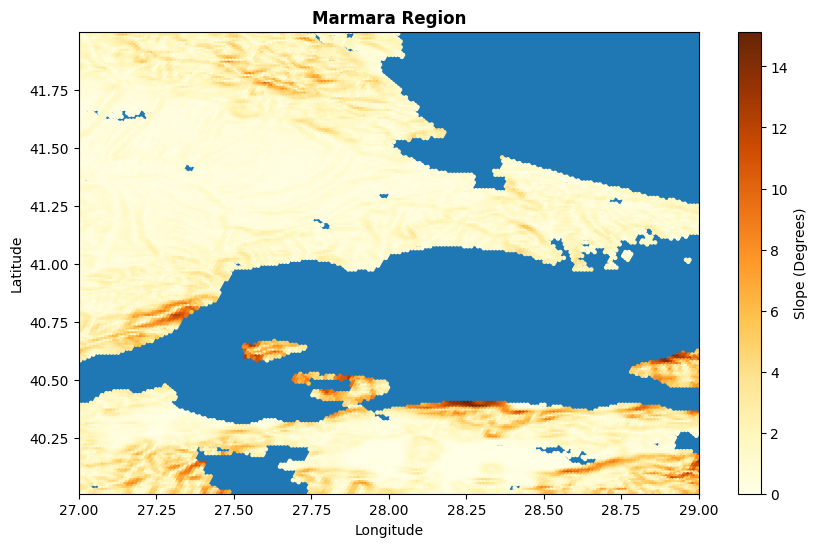

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_facecolor('#1f77b4')

sc = ax.scatter(
    df['Longitude'],
    df['Latitude'],
    c=df['Slope'],
    cmap='YlOrBr',
    s=5
)

plt.colorbar(sc, label='Slope (Degrees)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Marmara Region', fontsize=12, fontweight='bold')

plt.xlim(df['Longitude'].min(), df['Longitude'].max())
plt.ylim(df['Latitude'].min(), df['Latitude'].max())

plt.show()

## **the data set resulotion before dodwnscaling**

In [ ]:
xy = np.column_stack([x, y])
d, _ = cKDTree(xy).query(xy, k=2)
print(np.median(d[:, 1]))

928.6864094935155


In [ ]:
cell = 1895

tmp = pd.DataFrame({"x": x, "y": y, "dem":df["DEM"]})
tmp["cx"] = (tmp["x"] // cell).astype(int)
tmp["cy"] = (tmp["y"] // cell).astype(int)

coarse = tmp.groupby(["cx", "cy"], as_index=False)["dem"].mean()
coarse["x"] = (coarse["cx"] + 0.5) * cell
coarse["y"] = (coarse["cy"] + 0.5) * cell
print(len(coarse))

6011


## **the data set resulotion after  downscaling**

In [ ]:
xy2 = np.column_stack([coarse["x"].values, coarse["y"].values])
d2, _ = cKDTree(xy2).query(xy2, k=2)
print(np.median(d2[:, 1]))

1895.0


In [ ]:
df.head()

,Latitude,Longitude,Emis_31,Emis_32,NDVI,EVI,NDWI,Sun_Angle,Albedo_Diff,View_Angle,Rel_Azimuth,DEM,LST_Day_Celsius,LST_Night_Celsius,LST_Diff_Celsius,Slope,Slope_Diff,Temp_Diff
0,42.0,27.002363,0.984,0.986,0.3197,0.2274,0.161246,33.45,-0.010020,2.86,150.15,348.0,38.59,22.23,16.36,1.406365,18.593635,4.59
1,42.0,27.013577,0.984,0.988,0.3233,0.2282,0.144767,33.45,-0.014092,2.88,150.12,298.0,39.15,22.15,17.00,0.423101,19.576899,5.15
2,42.0,27.024791,0.984,0.986,0.3941,0.2979,0.233109,36.53,-0.032945,27.66,-22.09,312.0,39.53,22.45,17.08,1.230736,18.769264,5.53
3,42.0,27.036004,0.984,0.986,0.3629,0.2274,0.247936,30.54,-0.011009,32.04,151.75,367.0,39.47,22.93,16.54,2.203662,17.796338,5.47
4,42.0,27.047218,0.984,0.986,0.4203,0.3229,0.284582,36.51,-0.015603,27.50,-22.03,381.0,38.71,22.93,15.78,1.585066,18.414934,4.71


# **MOON DATA**

In [ ]:
dfmoon = pd.read_csv('/content/DEM_converted.csv')

In [ ]:
dfmoon.head(100)

,X,Y,DEM
0,-5457257.195,2728154.795,0.005178
1,-5455361.985,2728154.795,0.010570
2,-5453466.775,2728154.795,0.006543
3,-5451571.565,2728154.795,0.007897
4,-5449676.355,2728154.795,0.007362
...,...,...,...
95,-5277212.245,2728154.795,0.000242
96,-5275317.035,2728154.795,-0.005367
97,-5273421.825,2728154.795,-0.018607
98,-5271526.615,2728154.795,-0.019970


In [ ]:
rows, columns = dfmoon.shape

print("Number of Rows:", rows)
print("Number of Columns:", columns)

Number of Rows: 6539861
Number of Columns: 3


In [ ]:
df_moond = dfmoon.iloc[1000000:2000000].copy()

print("New DataFrame:")
display(df_moond)

print("Number of Rows:", len(df_moond))
print("Number of Columns:", df_moond.shape[1])

New DataFrame:


,X,Y,DEM
1000000,1213882.005,2400283.465,0.637884
1000001,1215777.215,2400283.465,0.622562
1000002,1217672.425,2400283.465,0.611145
1000003,1219567.635,2400283.465,0.588422
1000004,1221462.845,2400283.465,0.551520
...,...,...,...
1999995,-3040864.445,2070516.925,0.039183
1999996,-3038969.235,2070516.925,-0.041369
1999997,-3037074.025,2070516.925,-0.117401
1999998,-3035178.815,2070516.925,-0.167626


Number of Rows: 1000000
Number of Columns: 3


**selecting part of the moon**

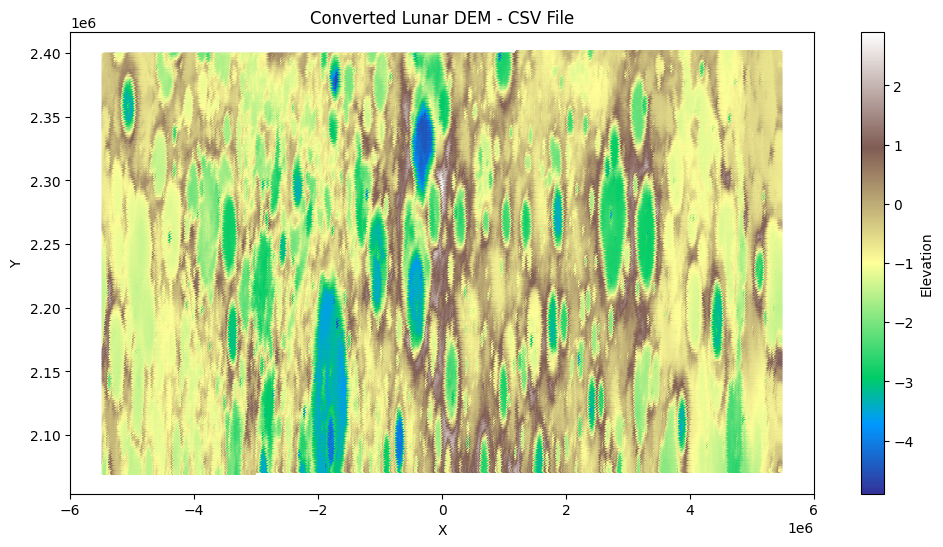

In [ ]:
plt.figure(figsize=(12, 6))
plt.scatter(
    df_moond['X'],
    df_moond['Y'],
    c=df_moond['DEM'],
    cmap='terrain',
    s=5
)

plt.colorbar(label='Elevation')
plt.title('Converted Lunar DEM - CSV File')
plt.xlabel('X')
plt.ylabel('Y')

plt.show()


*check the data and calculate the slope*

In [ ]:
print("NaN in X:", df_moond['X'].isna().sum())
print("NaN in Y:", df_moond['Y'].isna().sum())
print("NaN in DEM:", df_moond['DEM'].isna().sum())

print("Infinite in X:", np.isinf(df_moond['X']).sum())
print("Infinite in Y:", np.isinf(df_moond['Y']).sum())
print("Infinite in DEM:", np.isinf(df_moond['DEM']).sum())
bad_rows = df_moond[
    ~np.isfinite(df_moond[['X', 'Y', 'DEM']]).all(axis=1)
]

display(bad_rows)
print("Number of problematic rows:", len(bad_rows))
df_moond = df_moond.replace(
    [np.inf, -np.inf], np.nan
)

df_moond = df_moond.dropna(
    subset=['X', 'Y', 'DEM']
).reset_index(drop=True)
x = df_moond['X'].values
y = df_moond['Y'].values
print("X finite:", np.isfinite(x).all())
print("Y finite:", np.isfinite(y).all())

print("X shape:", x.shape)
print("Y shape:", y.shape)

NaN in X: 0
NaN in Y: 0
NaN in DEM: 0
Infinite in X: 0
Infinite in Y: 0
Infinite in DEM: 0


,X,Y,DEM


Number of problematic rows: 0
X finite: True
Y finite: True
X shape: (1000000,)
Y shape: (1000000,)


In [ ]:
coords = np.column_stack((
    df_moond['X'].values,
    df_moond['Y'].values
))

tree = cKDTree(coords)

distances, indices = tree.query(coords, k=12)

slopes = []

for i in range(len(df_moond)):

    neighbors = indices[i]

    X = df_moond['X'].values[neighbors] - df_moond['X'].values[i]
    Y = df_moond['Y'].values[neighbors] - df_moond['Y'].values[i]
    Z = df_moond['DEM'].values[neighbors]

    A = np.column_stack([
        X, Y, np.ones(len(X))
    ])

    a, b, c = np.linalg.lstsq(
        A, Z, rcond=None
    )[0]

    slope = np.degrees(
        np.arctan(np.sqrt(a**2 + b**2))
    )

    slopes.append(slope)

df_moond['Slope'] = slopes

display(df_moond[['X', 'Y', 'DEM', 'Slope']])

,X,Y,DEM,Slope
0,1213882.005,2400283.465,0.637884,0.001631
1,1215777.215,2400283.465,0.622562,0.001841
2,1217672.425,2400283.465,0.611145,0.002060
3,1219567.635,2400283.465,0.588422,0.002094
4,1221462.845,2400283.465,0.551520,0.002211
...,...,...,...,...
999995,-3040864.445,2070516.925,0.039183,0.004815
999996,-3038969.235,2070516.925,-0.041369,0.005471
999997,-3037074.025,2070516.925,-0.117401,0.005162
999998,-3035178.815,2070516.925,-0.167626,0.004894


# **visualizeeeee**

**

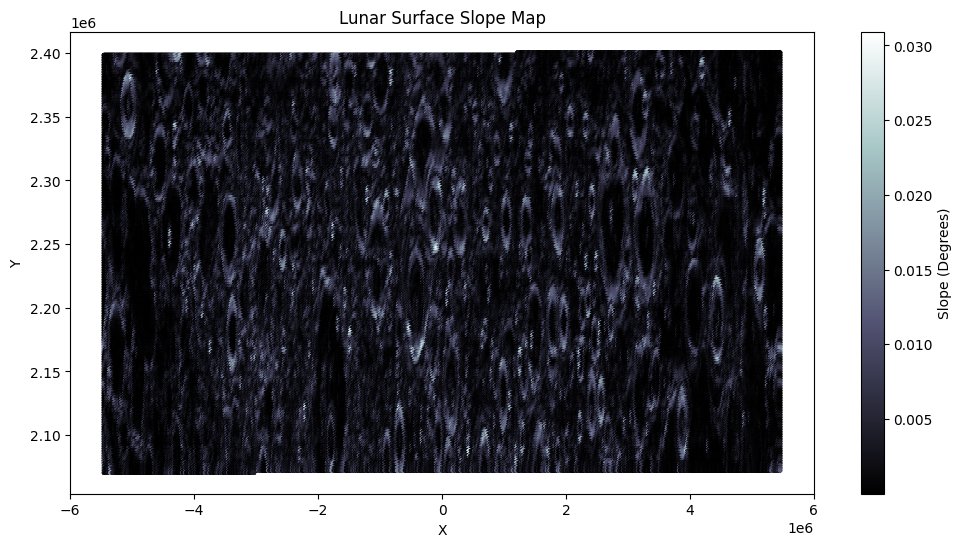

In [ ]:
plt.figure(figsize=(12, 6))

plt.scatter(
    df_moond['X'],
    df_moond['Y'],
    c=df_moond['Slope'],
    cmap='bone',
    s=5
)

plt.colorbar(label='Slope (Degrees)')
plt.title('Lunar Surface Slope Map')
plt.xlabel('X')
plt.ylabel('Y')

plt.show()

In [ ]:
!pip -q install ipympl

# **interactive map**

In [112]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import json
from IPython.display import display, FileLink
from google.colab import files



lunar_data = df_moond.dropna(
    subset=['X', 'Y', 'Slope']
).copy()

lunar_data = lunar_data[
    np.isfinite(
        lunar_data[['X', 'Y', 'Slope']]
    ).all(axis=1)
].reset_index(drop=True)


marmara_data = df.dropna(
    subset=['Longitude', 'Latitude', 'Slope']
).copy()

marmara_data = marmara_data[
    np.isfinite(
        marmara_data[['Longitude', 'Latitude', 'Slope']]
    ).all(axis=1)
].reset_index(drop=True)

marmara_json = json.dumps(
    marmara_data[
        ['Longitude', 'Latitude', 'Slope']
    ].values.tolist()
)

fig = go.Figure()

fig.add_trace(go.Scattergl(
    x=lunar_data['X'],
    y=lunar_data['Y'],
    mode='markers',

    customdata=lunar_data[['Slope']].values,

    marker=dict(
        color=lunar_data['Slope'],
        colorscale=[
            [0, '#666666'],
            [0.33, '#999999'],
            [0.66, '#CCCCCC'],
            [1, '#FFFFFF']
        ],
        cmin=0.005,
        cmax=0.030,
        size=4,
        colorbar=dict(title='Slope (Degrees)')
    ),

    hovertemplate=
        'X: %{x:.4f}<br>' +
        'Y: %{y:.4f}<br>' +
        'Slope: %{customdata[0]:.6f}°' +
        '<extra></extra>',

    name='Lunar Points'
))

fig.update_layout(
    title='Interactive MOON Slope Map',
    xaxis_title='X',
    yaxis_title='Y',
    template='plotly_white',
    height=650
)


post_script = r"""
const lunarPlot = document.getElementById('{plot_id}');

const marmaraData = __MARMARA_DATA__;

const info = document.createElement('div');

info.style.cssText = `
    padding: 15px;
    margin-top: 15px;
    font-family: Arial;
    background: #f3f3f3;
    border-radius: 8px;
    font-size: 15px;
`;

info.innerHTML = `
    <h3>Selected MOON Point</h3>
    Click any point on the Lunar map to find its Marmara match.
`;

lunarPlot.parentNode.insertBefore(
    info,
    lunarPlot.nextSibling
);

const marmaraDiv = document.createElement('div');

marmaraDiv.style.width = '100%';
marmaraDiv.style.height = '650px';

info.after(marmaraDiv);


lunarPlot.on('plotly_click', function(event) {

    const point = event.points[0];

    const lunarX = point.x;
    const lunarY = point.y;
    const targetSlope = Number(point.customdata[0]);

    // Find closest slope in the FULL Marmara dataset

    let best = null;
    let minDifference = Infinity;

    for (let i = 0; i < marmaraData.length; i++) {

        const row = marmaraData[i];

        const difference = Math.abs(
            row[2] - targetSlope
        );

        if (difference < minDifference) {

            minDifference = difference;
            best = row;

        }
    }

    const bestLon = best[0];
    const bestLat = best[1];
    const bestSlope = best[2];

    // Display selected lunar information

    info.innerHTML = `
        <h3>MOON Selected Point</h3>

        <b>X:</b> ${lunarX.toFixed(4)}<br>
        <b>Y:</b> ${lunarY.toFixed(4)}<br>
        <b>Slope:</b> ${targetSlope.toFixed(6)} degrees

        <hr>

        <h3>Best Marmara Match</h3>

        <b>Latitude:</b> ${bestLat.toFixed(6)}<br>
        <b>Longitude:</b> ${bestLon.toFixed(6)}<br>
        <b>Marmara Slope:</b> ${bestSlope.toFixed(6)} degrees<br>
        <b>Slope Difference:</b> ${minDifference.toFixed(6)} degrees
    `;


    // Create Marmara map

    const marmaraTrace = {
        x: marmaraData.map(row => row[0]),
        y: marmaraData.map(row => row[1]),

        mode: 'markers',
        type: 'scattergl',

        marker: {
            color: marmaraData.map(row => row[2]),
            colorscale: 'Greys',
            size: 4,
            colorbar: {
                title: 'Marmara Slope'
            }
        },

        name: 'Marmara Dataset'
    };


    // Highlight best matching point

    const bestTrace = {
        x: [bestLon],
        y: [bestLat],

        mode: 'markers',
        type: 'scatter',

        marker: {
            color: 'red',
            size: 18,
            symbol: 'star'
        },

        name: 'Best Match'
    };


    Plotly.react(
        marmaraDiv,
        [marmaraTrace, bestTrace],
        {
            title: 'Marmara - Best Slope Match',
            xaxis: {title: 'Longitude'},
            yaxis: {title: 'Latitude'},
            height: 650
        },
        {responsive: true}
    );

});
"""

post_script = post_script.replace(
    "__MARMARA_DATA__",
    marmara_json
)


output_file = "Lunar_Marmara_Interactive_Matching.html"

fig.write_html(
    output_file,
    full_html=True,
    include_plotlyjs=True,
    post_script=post_script
)

print("Interactive map created successfully!")

files.download(output_file)


Interactive map created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>